# XAI Evaluation: Faithfulness, Stability, Actionability and Human-Study Materials

The model notebooks show *what* each explanation says. This notebook tests whether those explanations deserve to be believed, which is what grading criteria 3 to 6 and 8 ask for. Every result below is a number computed from the code in this notebook.

**Model under evaluation.** The proposal stated that the model with the highest Fake-class recall would be carried forward for the full interpretability analysis. That model is the RBF-kernel SVM (`Model/Common Models/SVM.ipynb`), so it is the model evaluated here. The logistic regression baseline and the depth-3 decision tree are used as *white-box references*: their true reasoning is known, so we can check whether LIME and SHAP recover it.

| Section | Question | Grading criterion |
|---|---|---|
| 2 | Is the SVM meaningfully better than the baseline on the same test set? | 2, 7 |
| 3 | Do the explanations match what the models actually computed? | 3 (Faithfulness) |
| 4 | Do the explanations stay the same across random seeds and small input changes? | 4 (Stability) |
| 5 | What is the smallest edit that flips a decision, and what should the reviewer do with it? | 6 (Actionability) |
| 6 | Do errors concentrate on articles that mention protected groups? | 8 (Ethics) |
| 7 | Materials and scoring code for the forward-simulation study with participants | 5 (Human evidence) |

All models use the same cleaned data, preprocessing, TF-IDF settings, train/test split and seed (`RANDOM_STATE = 42`) as the model notebooks. Figures are written to `figures/` and all numbers to `results/xai_evaluation_results.json`, so the report can be regenerated from this notebook.

## 1. Setup

In [1]:
import os, sys, json, time, warnings
if not os.path.exists("preprocessing.py"):
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..", "..")))
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from scipy.stats import spearmanr, binomtest

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (recall_score, precision_score, accuracy_score,
                             confusion_matrix, roc_auc_score)
from lime.lime_text import LimeTextExplainer
import shap

from preprocessing import preprocess_text, get_split_tfidf, select_top_k_terms, RANDOM_STATE

warnings.filterwarnings("ignore", category=UserWarning)
FIG_DIR, RES_DIR, HUMAN_DIR = "figures", "results", "human_eval"
for d in (FIG_DIR, RES_DIR, HUMAN_DIR):
    os.makedirs(d, exist_ok=True)

RESULTS = {"random_state": RANDOM_STATE}     # every reported number is collected here

/home/claude/venv314/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1.1 Data, Split and Models

Same pipeline as every model notebook: title + text, `preprocess_text()`, a stratified 80/20 split, and TF-IDF fitted on the training articles only. The three models are trained with exactly the hyperparameters of their own notebooks.

The SVM takes several minutes to train, so the fitted model is cached in `Model/XAI Evaluation/svm_rbf.joblib` (ignored by git) after the first run. Delete the file to retrain from scratch.

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv.gz")
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)

X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)
feature_names = tfidf.get_feature_names_out()
vocab = tfidf.vocabulary_

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
test_raw = df.loc[y_test.index, "full_text"].reset_index(drop=True)
test_title = df.loc[y_test.index, "title"].reset_index(drop=True)
test_body = df.loc[y_test.index, "text"].reset_index(drop=True)
y_true = y_test.to_numpy()
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (30906, 5000)  Test: (7727, 5000)


In [3]:
lr = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000).fit(X_train, y_train)
dt = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=RANDOM_STATE).fit(X_train, y_train)

SVM_CACHE = "Model/XAI Evaluation/svm_rbf.joblib"
if os.path.exists(SVM_CACHE):
    svm_model = joblib.load(SVM_CACHE)
    print("Loaded cached SVM from", SVM_CACHE)
else:
    t0 = time.time()
    svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE).fit(X_train, y_train)
    joblib.dump(svm_model, SVM_CACHE)
    print(f"Trained SVM in {time.time() - t0:.0f} s and cached it")

svm_score = svm_model.decision_function(X_test)          # > 0 means fake
svm_pred = (svm_score > 0).astype(int)
lr_pred, dt_pred = lr.predict(X_test), dt.predict(X_test)

Loaded cached SVM from Model/XAI Evaluation/svm_rbf.joblib


The tests below score the SVM several hundred thousand times. `SVC.decision_function` takes about 8 ms per article on a laptop CPU, so we compute the same quantity directly from the fitted model's own parameters, f(x) = Σᵢ αᵢ yᵢ exp(−γ‖x − svᵢ‖²) + b, using sparse matrix products. The cell checks that it matches scikit-learn on the whole test set before it is used.

In [4]:
import scipy.sparse as sp
_SV = sp.csr_matrix(svm_model.support_vectors_)
_SVT = _SV.T.tocsr()
_sv_sq = np.asarray(_SV.multiply(_SV).sum(axis=1)).ravel()
_dual = np.asarray(sp.csr_matrix(svm_model.dual_coef_).todense()).ravel()
_b, _gamma = svm_model.intercept_[0], svm_model._gamma

def svm_decision(X):
    # exact RBF-SVM decision value from the fitted parameters (same result as svm_model.decision_function)
    X = sp.csr_matrix(X)
    x_sq = np.asarray(X.multiply(X).sum(axis=1)).ravel()
    K = np.exp(-_gamma * (x_sq[:, None] + _sv_sq[None, :] - 2 * (X @ _SVT).toarray()))
    return K @ _dual + _b

max_diff = np.abs(svm_decision(X_test) - svm_score).max()
assert max_diff < 1e-8, max_diff
print(f"Fast decision function matches scikit-learn on all {X_test.shape[0]} test articles (max difference {max_diff:.1e})")

def svm_decision_text(texts):
    # decision value of the SVM for raw processed texts (used by every perturbation test)
    return svm_decision(tfidf.transform(texts))

def svm_proba_text(texts):
    # LIME needs class scores in [0, 1]; same sigmoid of the decision value as in SVM.ipynb
    p = 1 / (1 + np.exp(-svm_decision_text(texts)))
    return np.column_stack([1 - p, p])

Fast decision function matches scikit-learn on all 7727 test articles (max difference 2.6e-12)


## 2. Model and Baseline on the Same Test Set (criteria 2 and 7)

The rubric asks us to say plainly whether the complex model is better than the simple one. Besides recall and accuracy, we report McNemar's exact test on the articles where the two models disagree (Dietterich, 1998) and a bootstrap 95% interval for the difference in Fake-class recall (1,000 resamples of the test set).

In [5]:
def metrics(pred, score):
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"fake_recall": recall_score(y_true, pred), "precision": precision_score(y_true, pred),
            "accuracy": accuracy_score(y_true, pred), "roc_auc": roc_auc_score(y_true, score),
            "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn)}

perf = pd.DataFrame({
    "Logistic regression (baseline)": metrics(lr_pred, lr.decision_function(X_test)),
    "Decision tree (depth 3)": metrics(dt_pred, dt.predict_proba(X_test)[:, 1]),
    "SVM, RBF kernel (explained model)": metrics(svm_pred, svm_score),
}).T
display(perf.round(4))
RESULTS["performance"] = {m: {k: (int(v) if k in ("TP", "FN", "FP", "TN") else round(float(v), 4)) for k, v in row.items()}
                          for m, row in perf.to_dict(orient="index").items()}

,fake_recall,precision,accuracy,roc_auc,TP,FN,FP,TN
Logistic regression (baseline),0.9690,0.9872,0.9803,0.9978,3381.0,108.0,44.0,4194.0
Decision tree (depth 3),0.9229,0.8344,0.8825,0.9361,3220.0,269.0,639.0,3599.0
"SVM, RBF kernel (explained model)",0.9751,0.9887,0.9837,0.9984,3402.0,87.0,39.0,4199.0


In [6]:
def mcnemar_exact(pred_a, pred_b, mask=None):
    mask = np.ones_like(y_true, bool) if mask is None else mask
    a_ok, b_ok = (pred_a == y_true)[mask], (pred_b == y_true)[mask]
    only_a, only_b = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    p = binomtest(min(only_a, only_b), only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    return only_a, only_b, p

b_all, c_all, p_all = mcnemar_exact(lr_pred, svm_pred)
b_fake, c_fake, p_fake = mcnemar_exact(lr_pred, svm_pred, mask=(y_true == 1))
print(f"All test articles : LR right & SVM wrong = {b_all}, SVM right & LR wrong = {c_all}, exact McNemar p = {p_all:.1e}")
print(f"Fake articles only: LR right & SVM wrong = {b_fake}, SVM right & LR wrong = {c_fake}, exact McNemar p = {p_fake:.1e}")

rng_boot = np.random.RandomState(RANDOM_STATE)
fake_idx = np.where(y_true == 1)[0]
diffs = []
for _ in range(1000):
    s = rng_boot.choice(fake_idx, size=len(fake_idx), replace=True)
    diffs.append((svm_pred[s] == 1).mean() - (lr_pred[s] == 1).mean())
ci = np.percentile(diffs, [2.5, 97.5])
d_rec = recall_score(y_true, svm_pred) - recall_score(y_true, lr_pred)
print(f"Fake-recall difference (SVM - LR) = {d_rec:+.4f}, bootstrap 95% CI [{ci[0]:+.4f}, {ci[1]:+.4f}]")

RESULTS["svm_vs_lr"] = {"discordant_all": [b_all, c_all], "mcnemar_p_all": p_all,
                        "discordant_fake": [b_fake, c_fake], "mcnemar_p_fake": p_fake,
                        "recall_diff": d_rec, "recall_diff_ci95": ci.tolist()}

All test articles : LR right & SVM wrong = 7, SVM right & LR wrong = 33, exact McNemar p = 4.2e-05
Fake articles only: LR right & SVM wrong = 3, SVM right & LR wrong = 24, exact McNemar p = 4.9e-05
Fake-recall difference (SVM - LR) = +0.0060, bootstrap 95% CI [+0.0032, +0.0089]


The SVM is ahead of the baseline by 0.6 points of Fake-class recall (bootstrap 95% CI 0.3 to 0.9 points) and 0.3 points of accuracy. The two models disagree on only 40 of the 7,727 test articles; the SVM is right on 33 of them (exact McNemar p = 4.2 × 10⁻⁵), including 24 of the 27 fake articles on which they disagree. The gain is small but not chance. Whether 21 fewer missed fakes per 7,727 articles justify giving up a model that explains itself is a judgement for the platform; we keep the SVM as the explained model because the proposal fixed that rule in advance and because its opacity is what the rest of this notebook tests.

### 2.1 Complexity of the Explained Model, in Numbers (criterion 7)

The rubric asks what makes the model opaque, stated with numbers.

In [7]:
n_sv = int(svm_model.n_support_.sum())
nnz_per_article = X_test.getnnz(axis=1)
complexity = {
    "kernel": "RBF", "C": 1.0, "gamma (scale)": float(svm_model._gamma),
    "input_dimensions": int(X_train.shape[1]), "support_vectors": n_sv,
    "support_vector_share_of_train": n_sv / X_train.shape[0],
    "median_nonzero_terms_per_test_article": int(np.median(nnz_per_article)),
}
display(pd.Series(complexity))
RESULTS["svm_complexity"] = complexity

kernel                                        RBF
C                                             1.0
gamma (scale)                            1.014249
input_dimensions                             5000
support_vectors                              7866
support_vector_share_of_train            0.254514
median_nonzero_terms_per_test_article         129
dtype: object

Each SVM decision is a weighted sum of RBF kernel values against 7,866 support vectors (25% of the training articles), each a 5,000-dimensional TF-IDF vector; a typical test article has 129 non-zero terms. No weight corresponds to a single word, so the model cannot be read by inspection. (`SVM.ipynb`, run on Windows, reports 7,865 support vectors; the one-vector difference comes from the platform, and every test prediction is identical.)

### 2.2 Sensitivity to Near-Duplicate Articles

`clean_dataset.ipynb` removes exact duplicate texts. Articles that differ only in punctuation, case or spacing become identical after `preprocess_text()`, and a few of them can sit on both sides of the split. We count the test articles whose first 300 processed characters also occur in the training set and recompute the scores without them. If the scores barely change, the near-duplicates do not inflate the results.

In [8]:
train_heads = set(df.loc[y_train.index, "processed_text"].str[:300])
near_dup = test_text.str[:300].isin(train_heads).to_numpy()
keep = ~near_dup
print(f"Test articles with a near-duplicate in training: {near_dup.sum()} "
      f"({near_dup.mean():.1%}); true labels: {pd.Series(y_true[near_dup]).map({0: 'real', 1: 'fake'}).value_counts().to_dict()}")
sens = pd.DataFrame({
    name: {"fake_recall (all)": recall_score(y_true, p), "fake_recall (no near-dups)": recall_score(y_true[keep], p[keep]),
           "accuracy (all)": accuracy_score(y_true, p), "accuracy (no near-dups)": accuracy_score(y_true[keep], p[keep])}
    for name, p in [("LR", lr_pred), ("SVM", svm_pred)]}).T
display(sens.round(4))
RESULTS["near_duplicates"] = {"n_test_near_dup": int(near_dup.sum()), "scores": sens.round(4).to_dict(orient="index")}

Test articles with a near-duplicate in training: 93 (1.2%); true labels: {'real': 93}


,fake_recall (all),fake_recall (no near-dups),accuracy (all),accuracy (no near-dups)
LR,0.9690,0.9690,0.9803,0.9801
SVM,0.9751,0.9751,0.9837,0.9835


93 test articles (1.2%) have a near-duplicate in training. All are real, so Fake-class recall cannot change; accuracy moves by 0.0002 without them, so the near-duplicates do not inflate the reported scores.

## 3. Faithfulness (criterion 3)

Faithfulness means the explanation matches what the model computed, not what looks plausible. We use the two tests the rubric names that fit text models:

1. **White-box checks.** We run LIME and SHAP on models whose true reasoning is known and measure how well they recover it: the logistic regression (exact per-word contributions are coefficient × TF-IDF weight) and the depth-3 decision tree (only five terms can matter).
2. **Deletion curve on the SVM.** If an explanation is faithful, deleting the words it ranks highest should move the SVM's decision value more than deleting the same number of random words (Samek et al., 2017).

### 3.1 White-Box Check A: LIME and KernelSHAP on the Logistic Regression

For a logistic regression, the exact contribution of word *w* to an article's log-odds is `coef[w] × tfidf[w]`. We explain 50 random test articles with LIME exactly as it is used in the model notebooks (1,000 perturbation samples) and compare its word weights with these exact contributions:

- **Spearman ρ** between LIME weights and exact contributions, over all vocabulary words in the article,
- **Precision@5**: share of LIME's five largest words (by |weight|) that are also among the five largest exact contributions,
- **Sign agreement** of LIME's top five words.

LIME removes whole words from the text, and TF-IDF re-normalises the remaining weights, so a perfect score is not expected even for a perfect explainer.

In [9]:
rng = np.random.RandomState(RANDOM_STATE)
wb_idx = rng.choice(len(test_text), size=50, replace=False)
lime_lr = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)
lr_proba_text = lambda texts: lr.predict_proba(tfidf.transform(texts))
coef = lr.coef_[0]

rows = []
for i in wb_idx:
    text = test_text.iloc[i]
    x = tfidf.transform([text]).toarray()[0]
    words = sorted({w for w in text.split() if w in vocab})
    exact = {w: coef[vocab[w]] * x[vocab[w]] for w in words}
    exp = lime_lr.explain_instance(text, lr_proba_text, num_features=len(set(text.split())),
                                   num_samples=1000, labels=(1,))
    lime_w = dict(exp.as_list(label=1))
    common = [w for w in words if w in lime_w]
    top5_exact = set(sorted(common, key=lambda w: -abs(exact[w]))[:5])
    top5_lime = sorted(common, key=lambda w: -abs(lime_w[w]))[:5]
    rows.append({"spearman_rho": spearmanr([lime_w[w] for w in common], [exact[w] for w in common]).correlation,
                 "precision_at_5": len(top5_exact & set(top5_lime)) / 5,
                 "sign_agreement_top5": np.mean([np.sign(lime_w[w]) == np.sign(exact[w]) for w in top5_lime])})
wb_lr = pd.DataFrame(rows)
display(wb_lr.describe().loc[["mean", "std", "min", "50%", "max"]].round(3))
RESULTS["whitebox_lr_lime"] = wb_lr.agg(["mean", "std", "min", "median"]).round(3).to_dict()

,spearman_rho,precision_at_5,sign_agreement_top5
mean,0.810,0.836,0.992
std,0.141,0.132,0.040
min,0.458,0.600,0.800
50%,0.850,0.800,1.000
max,0.989,1.000,1.000


LIME recovers the baseline's true word contributions well but not perfectly: mean Spearman ρ = 0.81 (lowest article 0.46), 84% of its top-5 words are among the five largest true contributions, and 99% of its top-5 words have the correct sign. Part of the gap comes from TF-IDF re-normalisation when LIME deletes words, so exact agreement is not expected. On this linear model, the sign and the top few words of a LIME explanation can be trusted and the order beyond the top five is less reliable; note that these runs used 1,000 samples, while `SVM.ipynb` uses 500.

KernelSHAP is used on the SVM with a specific set-up (top-30 chi-squared terms, background = term absent, 500 samples; `SVM.ipynb`, Section 9.2). Applied to the logistic regression's decision function, the exact Shapley value of each of the 30 terms is `coef × tfidf`, because the model is linear in the TF-IDF vector. This checks that the set-up itself is correct.

In [10]:
top_idx, top_terms, _ = select_top_k_terms(X_train, y_train, feature_names, k=30, method="chi2")

def kernel_shap_topk(model_fn, x_row, top_idx, nsamples=500, seed=RANDOM_STATE):
    # same function as SVM.ipynb Section 9.2, with an explicit seed
    def f(Z):
        full = np.tile(x_row, (Z.shape[0], 1))
        full[:, top_idx] = Z
        return model_fn(full)
    np.random.seed(seed)
    explainer = shap.KernelExplainer(f, np.zeros((1, len(top_idx))))
    return explainer.shap_values(x_row[top_idx].reshape(1, -1), nsamples=nsamples, silent=True)[0]

X_test_dense = X_test.toarray()
ks_err, ks_corr = [], []
for i in wb_idx:
    v = kernel_shap_topk(lr.decision_function, X_test_dense[i], top_idx)
    exact = coef[top_idx] * X_test_dense[i, top_idx]
    ks_err.append(np.abs(v - exact).max())
    if (exact != 0).sum() >= 3:
        ks_corr.append(np.corrcoef(v, exact)[0, 1])
print(f"KernelSHAP vs exact contributions (50 articles): median max-abs error = {np.median(ks_err):.2e}, "
      f"worst article = {np.max(ks_err):.3f}; mean Pearson r = {np.mean(ks_corr):.4f} (n = {len(ks_corr)} articles with >= 3 top terms)")
RESULTS["whitebox_lr_kernelshap"] = {"median_max_abs_err": float(np.median(ks_err)), "worst_max_abs_err": float(np.max(ks_err)),
                                     "mean_pearson": float(np.mean(ks_corr)), "n_corr": len(ks_corr),
                                     "share_articles_err_below_0.01": float(np.mean(np.array(ks_err) < 0.01))}

KernelSHAP vs exact contributions (50 articles): median max-abs error = 3.19e-16, worst article = 0.292; mean Pearson r = 0.9954 (n = 40 articles with >= 3 top terms)


For 46 of the 50 articles (92%), KernelSHAP recovers coefficient × TF-IDF weight to within 0.01, and the median error is at machine precision: when an article contains few of the 30 terms, 500 samples cover every coalition. The worst article (error 0.29) contains many of the 30 terms, where 500 samples no longer cover every coalition. The KernelSHAP set-up used on the SVM is therefore correct, with sampling error only on term-rich articles.

### 3.2 White-Box Check B: LIME and TreeSHAP on the Decision Tree

The tree uses only five terms (via, said, video, reuters, ministry). A faithful explainer should put (almost) all of its weight on these five terms and none on the other 4,995. For 100 random test articles we measure the share of LIME's absolute weight (top 5 words, 1,000 samples) that falls on the tree's terms, and whether LIME's top word is one of them. For TreeSHAP we check that every unused term gets exactly zero and that the values add up to the prediction.

In [11]:
used_terms = set(feature_names[np.unique(dt.tree_.feature[dt.tree_.feature >= 0])])
lime_dt = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)
dt_proba_text = lambda texts: dt.predict_proba(tfidf.transform(texts))

rng = np.random.RandomState(RANDOM_STATE)
dt_idx = rng.choice(len(test_text), size=100, replace=False)
rows = []
for i in dt_idx:
    text = test_text.iloc[i]
    lst = lime_dt.explain_instance(text, dt_proba_text, num_features=5, num_samples=1000, labels=(1,)).as_list(label=1)
    total = sum(abs(v) for _, v in lst)
    has_used = bool(used_terms & set(text.split()))
    rows.append({"contains_a_tree_term": has_used,
                 "weight_share_on_tree_terms": sum(abs(v) for w, v in lst if w in used_terms) / total if total > 0 else np.nan,
                 "top1_is_tree_term": lst[0][0] in used_terms})
wb_dt = pd.DataFrame(rows)
sub = wb_dt[wb_dt.contains_a_tree_term]
print(f"Articles containing at least one tree term: {len(sub)} of {len(wb_dt)}")
print(f"  LIME weight share on tree terms: mean {sub.weight_share_on_tree_terms.mean():.3f}, median {sub.weight_share_on_tree_terms.median():.3f}")
print(f"  LIME top word is a tree term: {sub.top1_is_tree_term.mean():.1%}")
nosub = wb_dt[~wb_dt.contains_a_tree_term]
print(f"Articles with none of the tree terms: {len(nosub)}; LIME top word is a tree term in {nosub.top1_is_tree_term.mean():.0%} "
      "(it cannot be, since LIME can only remove words that are present)")

tree_exp = shap.TreeExplainer(dt)
X_dt = X_test[dt_idx].toarray()
sv = tree_exp.shap_values(X_dt)
sv = sv[:, :, 1] if np.ndim(sv) == 3 else sv
unused_mask = ~np.isin(feature_names, list(used_terms))
add_err = np.abs(sv.sum(axis=1) + np.ravel(tree_exp.expected_value)[-1] - dt.predict_proba(X_dt)[:, 1]).max()
print(f"TreeSHAP: max |value| on the 4,995 unused terms = {np.abs(sv[:, unused_mask]).max():.1e}; max additivity error = {add_err:.1e}")
RESULTS["whitebox_dt"] = {"n_with_tree_term": int(len(sub)),
                          "lime_weight_share_on_tree_terms_mean": float(sub.weight_share_on_tree_terms.mean()),
                          "lime_weight_share_on_tree_terms_median": float(sub.weight_share_on_tree_terms.median()),
                          "lime_top1_is_tree_term": float(sub.top1_is_tree_term.mean()),
                          "treeshap_max_unused": float(np.abs(sv[:, unused_mask]).max()), "treeshap_additivity_err": float(add_err)}

Articles containing at least one tree term: 92 of 100
  LIME weight share on tree terms: mean 0.895, median 0.994
  LIME top word is a tree term: 97.8%
Articles with none of the tree terms: 8; LIME top word is a tree term in 0% (it cannot be, since LIME can only remove words that are present)
TreeSHAP: max |value| on the 4,995 unused terms = 0.0e+00; max additivity error = 2.2e-16


In the 92 articles that contain at least one tree term, a median 99.4% (mean 89.5%) of LIME's weight lands on the tree's five terms, and LIME's top word is a tree term in 97.8% of them. TreeSHAP gives exactly zero to all 4,995 unused terms and its values add up to the prediction (error 2 × 10⁻¹⁶). Both methods report the known model correctly. LIME's blind spot shows in the other 8 articles: it cannot attribute anything to a word that is absent, such as a missing "via", which TreeSHAP can.

### 3.3 Deletion Curve on the SVM

For 100 random test articles (50 fake, 50 real), we explain the SVM's prediction with LIME, exactly as in `SVM.ipynb` (500 samples, sigmoid of the decision value). We ask LIME for its 30 highest-weighted words, rank them by how strongly LIME says they support the predicted class, delete the top *k* words (every occurrence) for *k* = 1 to 10, and record how far the decision value moves toward the other class. The comparison is deleting *k* random words from the same article (5 random draws, averaged).

- **AOPC** (area over the perturbation curve): the average move over *k* = 1 to 10, in decision-value units. Higher means the explanation found words the SVM actually relies on.
- **Flip rate**: share of articles whose predicted class changes after *k* deletions.

In [12]:
K_MAX, N_RANDOM = 10, 5
rng = np.random.RandomState(RANDOM_STATE)
del_idx = np.concatenate([rng.choice(np.where(y_true == c)[0], 50, replace=False) for c in (1, 0)])
lime_svm = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def delete_words(text, words):
    drop = set(words)
    return " ".join(t for t in text.split() if t not in drop)

t0 = time.time()
curves_lime, curves_rand, flips_lime, flips_rand, n_support = [], [], [], [], []
for i in del_idx:
    text = test_text.iloc[i]
    f0 = svm_score[i]
    sgn = 1 if f0 > 0 else -1                       # a move toward the other class counts as positive
    exp = lime_svm.explain_instance(text, svm_proba_text, num_features=30, num_samples=500, labels=(1,))
    ranked = [w for w, wt in sorted(exp.as_list(label=1), key=lambda t: -sgn * t[1]) if sgn * wt > 0][:K_MAX]
    n_support.append(len(ranked))
    ranked += [None] * (K_MAX - len(ranked))        # fewer supporting words than K_MAX: curve stays flat
    variants = [delete_words(text, [w for w in ranked[:k] if w]) for k in range(1, K_MAX + 1)]
    uniq = sorted(set(text.split()))
    for _ in range(N_RANDOM):
        perm = list(rng.permutation(uniq))
        variants += [delete_words(text, perm[:k]) for k in range(1, K_MAX + 1)]
    f = svm_decision_text(variants)
    f_lime, f_rand = f[:K_MAX], f[K_MAX:].reshape(N_RANDOM, K_MAX)
    curves_lime.append(sgn * (f0 - f_lime))
    curves_rand.append((sgn * (f0 - f_rand)).mean(axis=0))
    flips_lime.append(np.sign(f_lime) != np.sign(f0))
    flips_rand.append((np.sign(f_rand) != np.sign(f0)).mean(axis=0))
curves_lime, curves_rand = np.array(curves_lime), np.array(curves_rand)
flip_lime, flip_rand = np.array(flips_lime).mean(axis=0), np.array(flips_rand).mean(axis=0)
print(f"Deletion test done in {time.time() - t0:.0f} s; articles with fewer than {K_MAX} supporting words in LIME's top 30: {np.sum(np.array(n_support) < K_MAX)}")

Deletion test done in 26 s; articles with fewer than 10 supporting words in LIME's top 30: 2


AOPC (k = 1..10): LIME = 0.853, random = 0.044  (ratio 19.5x); LIME beats random on 100% of articles
Flip rate after 5 deletions : LIME 17%, random 0%
Flip rate after 10 deletions: LIME 31%, random 1%
Median |decision value| of these articles: 1.41


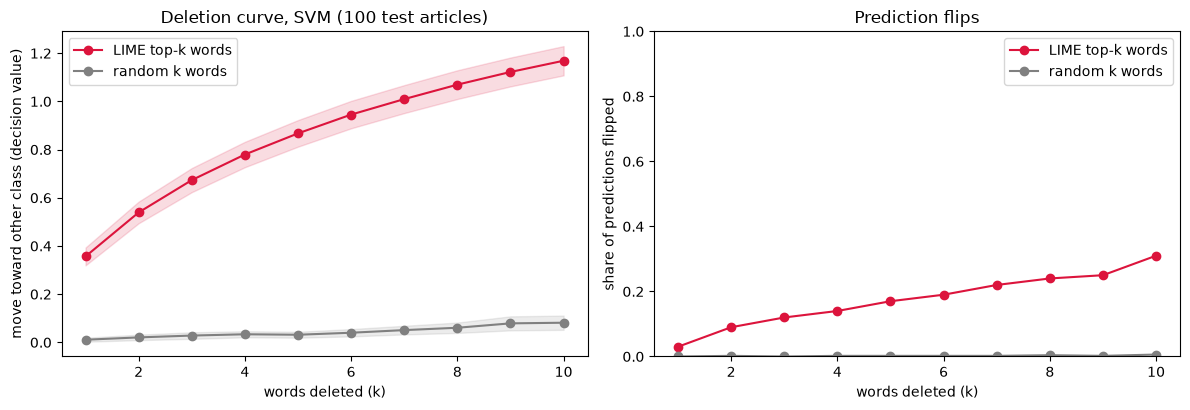

In [13]:
f0_abs = np.abs(svm_score[del_idx])
aopc_lime, aopc_rand = curves_lime.mean(axis=1), curves_rand.mean(axis=1)
win_rate = (aopc_lime > aopc_rand).mean()
print(f"AOPC (k = 1..10): LIME = {aopc_lime.mean():.3f}, random = {aopc_rand.mean():.3f}  "
      f"(ratio {aopc_lime.mean() / aopc_rand.mean():.1f}x); LIME beats random on {win_rate:.0%} of articles")
print(f"Flip rate after 5 deletions : LIME {flip_lime[4]:.0%}, random {flip_rand[4]:.0%}")
print(f"Flip rate after 10 deletions: LIME {flip_lime[9]:.0%}, random {flip_rand[9]:.0%}")
print(f"Median |decision value| of these articles: {np.median(f0_abs):.2f}")

ks = np.arange(1, K_MAX + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for curves, label, color in [(curves_lime, "LIME top-k words", "crimson"), (curves_rand, "random k words", "grey")]:
    m = curves.mean(axis=0); se = curves.std(axis=0, ddof=1) / np.sqrt(len(curves))
    axes[0].plot(ks, m, marker="o", color=color, label=label)
    axes[0].fill_between(ks, m - 1.96 * se, m + 1.96 * se, color=color, alpha=0.15)
axes[0].set_xlabel("words deleted (k)"); axes[0].set_ylabel("move toward other class (decision value)")
axes[0].set_title("Deletion curve, SVM (100 test articles)"); axes[0].legend()
axes[1].plot(ks, flip_lime, marker="o", color="crimson", label="LIME top-k words")
axes[1].plot(ks, flip_rand, marker="o", color="grey", label="random k words")
axes[1].set_xlabel("words deleted (k)"); axes[1].set_ylabel("share of predictions flipped"); axes[1].set_ylim(0, 1)
axes[1].set_title("Prediction flips"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_deletion_curve_svm.png", dpi=150); plt.show()

RESULTS["deletion_svm"] = {"n_articles": len(del_idx), "lime_num_samples": 500, "k_max": K_MAX,
                           "aopc_lime": float(aopc_lime.mean()), "aopc_random": float(aopc_rand.mean()),
                           "lime_beats_random_share": float(win_rate),
                           "flip_lime": flip_lime.round(3).tolist(), "flip_random": flip_rand.round(3).tolist(),
                           "median_abs_decision": float(np.median(f0_abs))}

Deleting the words LIME ranks highest moves the SVM's decision value 19.5 times as far as deleting the same number of random words (AOPC 0.85 vs 0.04 decision-value units), and LIME beats random on all 100 articles. After five deletions 17% of predictions flip, against 0% for random deletions (31% vs 1% after ten). LIME's rankings therefore point at words the SVM actually relies on. Most predictions survive ten deletions because the median article sits 1.41 units from the boundary, which matches the PFI result in `SVM.ipynb`: the SVM spreads its decision over many words.

## 4. Stability (criterion 4)

**Protocol.** We chose 20 test articles (10 fake, 10 real, drawn at random with the project seed) and ran three tests on the SVM:

1. **Seed stability of LIME.** Each article is explained with 10 different seeds at 500 samples (the setting used in `SVM.ipynb`) and with 5 seeds at 2,000 samples (what we tried to improve stability). Agreement between two runs is the **Jaccard index of their top-5 words** (1 = same five words, 0 = no overlap), averaged over all pairs of runs. We also report how often the single top word is the same.
2. **Seed stability of KernelSHAP** (top-30 set-up of `SVM.ipynb`), 5 seeds per article, measured the same way on the terms with non-zero values.
3. **Input perturbation.** We delete 5% of each article's tokens at random, never touching the words in the original top 10 of LIME, so the evidence LIME pointed at is still there. We keep perturbations that move the SVM's sigmoid score by less than 0.05, explain the original and perturbed article with the same seed at 2,000 samples, and compare their top-5 words. If this Jaccard index is close to the seed-only Jaccard at 2,000 samples, the explanation moves no more than LIME's own sampling noise.

Top-5 was chosen because the model notebooks show and discuss about five to seven words per article, and a reviewer would read the top few.

In [14]:
def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else 1.0

def top_words(exp, k=5):
    return [w for w, _ in sorted(exp.as_list(label=1), key=lambda t: -abs(t[1]))[:k]]

rng = np.random.RandomState(RANDOM_STATE + 2)
stab_idx = np.concatenate([rng.choice(np.where(y_true == c)[0], 10, replace=False) for c in (1, 0)])

t0 = time.time()
seed_runs = {500: {}, 2000: {}}
for n_samples, seeds in [(500, range(10)), (2000, range(5))]:
    for i in stab_idx:
        runs = []
        for s in seeds:
            e = LimeTextExplainer(class_names=["real", "fake"], random_state=s).explain_instance(
                test_text.iloc[i], svm_proba_text, num_features=10, num_samples=n_samples, labels=(1,))
            runs.append(e)
        seed_runs[n_samples][i] = runs
print(f"LIME seed runs done in {time.time() - t0:.0f} s")

def pairwise_stats(runs):
    tops = [top_words(e) for e in runs]
    pairs = [(a, b) for a in range(len(tops)) for b in range(a + 1, len(tops))]
    return (np.mean([jaccard(tops[a], tops[b]) for a, b in pairs]),
            np.mean([tops[a][0] == tops[b][0] for a, b in pairs]))

stab = []
for n_samples in (500, 2000):
    for i in stab_idx:
        j, t1 = pairwise_stats(seed_runs[n_samples][i])
        stab.append({"num_samples": n_samples, "article": i, "label": "fake" if y_true[i] else "real",
                     "jaccard_top5": j, "same_top1": t1})
stab = pd.DataFrame(stab)
summary = stab.groupby("num_samples")[["jaccard_top5", "same_top1"]].agg(["mean", "min"]).round(3)
display(summary)
print("Articles with mean Jaccard < 0.5:", stab.groupby("num_samples").apply(lambda g: int((g.jaccard_top5 < 0.5).sum())).to_dict())
RESULTS["stability_lime_seed"] = {str(k): v for k, v in stab.groupby("num_samples")[["jaccard_top5", "same_top1"]].mean().round(3).to_dict(orient="index").items()}
RESULTS["stability_lime_seed_min"] = {str(k): v for k, v in stab.groupby("num_samples")[["jaccard_top5"]].min().round(3).to_dict(orient="index").items()}

LIME seed runs done in 150 s


jaccard_top5        same_top1       
                    mean    min      mean    min
num_samples                                     
500                0.780  0.590     0.909  0.289
2000               0.872  0.652     0.940  0.600

Articles with mean Jaccard < 0.5: {500: 0, 2000: 0}


At the setting used in `SVM.ipynb` (500 samples), two LIME runs with different seeds share on average 78% of their top-5 words (Jaccard 0.78, worst article 0.59), and the top word agrees in 91% of seed pairs (worst article 29%). Raising the sample count to 2,000, which is what we tried, improves this to 0.87 and 94% at four times the cost. No article falls below 0.5. LIME is therefore moderately stable: the top word can usually be relied on, while the rest of a seven-word bar chart should be read as indicative. This is what we would tell the reviewer, and why the human-study forms use 2,000 samples.

In [15]:
X_stab = X_test[stab_idx].toarray()
ks_stab = []
for j, i in enumerate(stab_idx):
    vals = [kernel_shap_topk(svm_decision, X_stab[j], top_idx, nsamples=500, seed=s) for s in range(5)]
    tops = [[top_terms[t] for t in np.argsort(-np.abs(v))[:5] if v[t] != 0] for v in vals]
    pairs = [(a, b) for a in range(5) for b in range(a + 1, 5)]
    ks_stab.append({"jaccard_top5": np.mean([jaccard(tops[a], tops[b]) for a, b in pairs]),
                    "max_abs_diff": max(np.abs(vals[a] - vals[b]).max() for a, b in pairs),
                    "n_top30_terms_present": int((X_stab[j, top_idx] > 0).sum())})
ks_stab = pd.DataFrame(ks_stab)
display(ks_stab.describe().loc[["mean", "min", "max"]].round(4))
RESULTS["stability_kernelshap_seed"] = {"jaccard_top5_mean": float(ks_stab.jaccard_top5.mean()),
                                        "jaccard_top5_min": float(ks_stab.jaccard_top5.min()),
                                        "max_abs_diff_max": float(ks_stab.max_abs_diff.max())}

,jaccard_top5,max_abs_diff,n_top30_terms_present
mean,0.9883,0.0029,5.3
min,0.7667,0.0000,1.0
max,1.0000,0.0433,14.0


KernelSHAP restricted to the 30 top terms is almost deterministic (mean Jaccard 0.99; the largest change in any value across seeds is 0.043 decision units), because most articles contain only a handful (mean 5.3) of the 30 terms.

In [16]:
rng = np.random.RandomState(RANDOM_STATE + 3)
pert_rows = []
for i in stab_idx:
    text = test_text.iloc[i]
    ref = LimeTextExplainer(class_names=["real", "fake"], random_state=0).explain_instance(
        text, svm_proba_text, num_features=10, num_samples=2000, labels=(1,))
    protected = {w for w, _ in ref.as_list(label=1)}           # original top-10 words are never deleted
    tokens = text.split()
    p0 = svm_proba_text([text])[0, 1]
    for rep in range(2):
        candidates = [k for k, t in enumerate(tokens) if t not in protected]
        n_drop = max(1, int(round(0.05 * len(tokens))))
        drop = set(rng.choice(candidates, size=min(n_drop, len(candidates)), replace=False))
        pert = " ".join(t for k, t in enumerate(tokens) if k not in drop)
        p1 = svm_proba_text([pert])[0, 1]
        e = LimeTextExplainer(class_names=["real", "fake"], random_state=0).explain_instance(
            pert, svm_proba_text, num_features=10, num_samples=2000, labels=(1,))
        pert_rows.append({"article": i, "score_change": abs(p1 - p0), "tokens_deleted": len(drop),
                          "jaccard_top5": jaccard(top_words(ref), top_words(e)),
                          "same_top1": top_words(ref)[0] == top_words(e)[0]})
pert = pd.DataFrame(pert_rows)
small = pert[pert.score_change < 0.05]
seed_j2000 = stab[stab.num_samples == 2000].jaccard_top5.mean()
print(f"Perturbations kept (score change < 0.05): {len(small)} of {len(pert)}; median score change {small.score_change.median():.4f}")
print(f"Top-5 Jaccard, original vs perturbed (same seed): {small.jaccard_top5.mean():.3f}  | same top word: {small.same_top1.mean():.0%}")
print(f"Top-5 Jaccard, same article, different seeds (2,000 samples): {seed_j2000:.3f}")
RESULTS["stability_perturbation"] = {"n_kept": int(len(small)), "n_total": int(len(pert)),
                                     "median_score_change": float(small.score_change.median()),
                                     "jaccard_top5": float(small.jaccard_top5.mean()), "same_top1": float(small.same_top1.mean()),
                                     "seed_only_jaccard_2000": float(seed_j2000)}

Perturbations kept (score change < 0.05): 40 of 40; median score change 0.0028
Top-5 Jaccard, original vs perturbed (same seed): 0.877  | same top word: 92%
Top-5 Jaccard, same article, different seeds (2,000 samples): 0.872


Deleting 5% of an article's tokens (outside LIME's top 10) moved the SVM's score by a median of 0.003. The perturbed article's explanation shares its top-5 words with the original at Jaccard 0.877 (top word unchanged in 92%), the same as the agreement between two seeds on the unchanged article (0.872). On average, small irrelevant edits therefore do not move the explanation beyond LIME's own sampling noise; the worst perturbed article drops to 0.43, against 0.65 for the worst seed-only article. The test is deliberately mild, since it never deletes the words LIME pointed at.

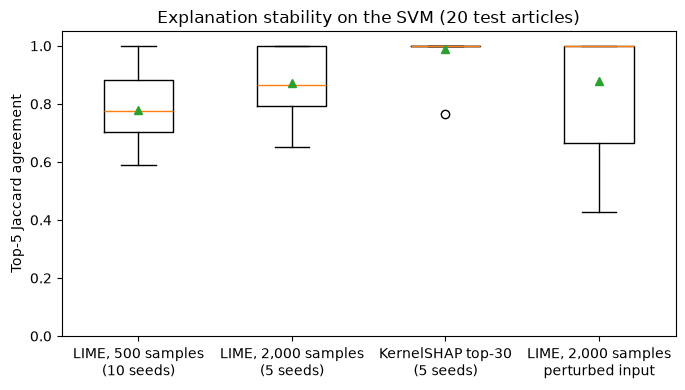

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
labels = ["LIME, 500 samples\n(10 seeds)", "LIME, 2,000 samples\n(5 seeds)", "KernelSHAP top-30\n(5 seeds)", "LIME, 2,000 samples\nperturbed input"]
vals = [stab[stab.num_samples == 500].jaccard_top5, stab[stab.num_samples == 2000].jaccard_top5, ks_stab.jaccard_top5, small.jaccard_top5]
ax.boxplot(vals, tick_labels=labels, showmeans=True)
ax.set_ylabel("Top-5 Jaccard agreement"); ax.set_ylim(0, 1.05)
ax.set_title("Explanation stability on the SVM (20 test articles)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_stability_svm.png", dpi=150); plt.show()

## 5. Actionability: Counterfactual Edits (criterion 6)

**Mutable and immutable inputs.** The models only read the article's words. `date` cannot be changed and `subject` is set by the publisher's site; both are excluded anyway because they leak the label. Among the words, we separate two kinds:

- **Source/format artefacts** (technically mutable, but changing them games the model): the fingerprint terms from the baseline notebook, Section 8.1 (reuters, via, image, images, featured, getty, com, http, www, pic, twitter, wire, read, video, watch). They identify the website and page layout, not the content. Telling a publisher to delete a photo credit is gaming the model, not improving the article.
- **Editorial wording** (mutable): every other word, such as attribution ("said", "told"), tone and word choice.

**Method.** For a flagged article, we look for a small set of words whose deletion makes the SVM call it real, using a greedy search in the style of SEDC (Martens & Provost, 2014; greedy, so the set is not guaranteed to be minimal): at each step, delete the word that lowers the decision value most, and stop when the prediction flips or 20 words have been deleted. Candidates are the 40 words with the largest single-deletion effect. We run it twice: with all words allowed, and with editorial words only. We apply it to all real articles that the SVM wrongly flagged (false positives) and to 40 random correctly flagged fakes (true positives).

In [18]:
ARTEFACTS = {"reuters", "via", "image", "images", "featured", "getty", "com", "http", "www",
             "pic", "twitter", "wire", "read", "video", "watch"}
MAX_EDITS, N_CAND = 20, 40

def counterfactual(text, allowed=lambda w: True):
    words = sorted({w for w in text.split() if allowed(w)})
    if not words:
        return None
    f0 = svm_decision_text([text])[0]
    single = svm_decision_text([delete_words(text, [w]) for w in words])
    cand = [words[k] for k in np.argsort(single)[:N_CAND]]           # largest single-deletion drops
    removed, current = [], f0
    while current > 0 and len(removed) < MAX_EDITS and cand:
        trial = svm_decision_text([delete_words(text, removed + [w]) for w in cand])
        best = int(np.argmin(trial))
        removed.append(cand.pop(best)); current = trial[best]
    return {"size": float(len(removed)) if current <= 0 else np.nan, "words": removed, "f0": f0, "f_end": current}

fp_idx = np.where((y_true == 0) & (svm_pred == 1))[0]
rng = np.random.RandomState(RANDOM_STATE + 4)
tp_idx = rng.choice(np.where((y_true == 1) & (svm_pred == 1))[0], 40, replace=False)

t0 = time.time()
cf_rows = []
for group, idxs in [("FP (real, flagged)", fp_idx), ("TP (fake, flagged)", tp_idx)]:
    for i in idxs:
        text = test_text.iloc[i]
        free = counterfactual(text)
        edit = counterfactual(text, allowed=lambda w: w not in ARTEFACTS)
        free_ok = not np.isnan(free["size"])
        edit_ok = edit is not None and not np.isnan(edit["size"])
        cf_rows.append({"group": group, "article": i, "decision_value": svm_score[i],
                        "cf_size_any": free["size"],
                        "cf_any_uses_artefact": float(bool(set(free["words"]) & ARTEFACTS)) if free_ok else np.nan,
                        "cf_size_editorial": edit["size"] if edit_ok else np.nan,
                        "cf_words_any": ", ".join(free["words"]) if free_ok else "(no flip within 20)",
                        "cf_words_editorial": ", ".join(edit["words"]) if edit_ok else "(no flip within 20)"})
cf = pd.DataFrame(cf_rows)
print(f"Counterfactual search done in {time.time() - t0:.0f} s")

Counterfactual search done in 58 s


,n,flipped within 20 (any word),median size (any word),flipped within 3 (any word),uses an artefact word,flipped within 20 (editorial only),median size (editorial only),flipped within 3 (editorial only)
group,,,,,,,,
"FP (real, flagged)",39.0,0.974,1.0,0.718,0.237,0.974,2.0,0.641
"TP (fake, flagged)",40.0,0.675,9.0,0.050,0.963,0.250,9.5,0.025


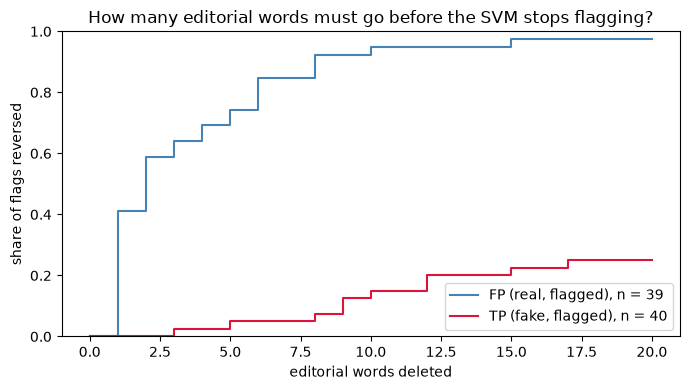

Spearman rho between decision value and editorial counterfactual size (flipped cases, n = 48): 0.82
Median decision value: FP 0.25 | TP 1.24


In [19]:
def cf_summary(g):
    return pd.Series({
        "n": len(g),
        "flipped within 20 (any word)": g.cf_size_any.notna().mean(),
        "median size (any word)": g.cf_size_any.median(),
        "flipped within 3 (any word)": (g.cf_size_any <= 3).mean(),
        "uses an artefact word": g.cf_any_uses_artefact.mean(),
        "flipped within 20 (editorial only)": g.cf_size_editorial.notna().mean(),
        "median size (editorial only)": g.cf_size_editorial.median(),
        "flipped within 3 (editorial only)": (g.cf_size_editorial <= 3).mean(),
    })
cf_table = cf.groupby("group").apply(cf_summary)
display(cf_table.round(3))
RESULTS["counterfactuals"] = cf_table.round(3).to_dict(orient="index")

ks_cf = np.arange(0, MAX_EDITS + 1)
fig, ax = plt.subplots(figsize=(7, 4))
for g, color in [("FP (real, flagged)", "steelblue"), ("TP (fake, flagged)", "crimson")]:
    sizes = cf.loc[cf.group == g, "cf_size_editorial"]
    ax.step(ks_cf, [(sizes <= k).mean() for k in ks_cf], where="post", color=color, label=f"{g}, n = {len(sizes)}")
ax.set_xlabel("editorial words deleted"); ax.set_ylabel("share of flags reversed"); ax.set_ylim(0, 1)
ax.set_title("How many editorial words must go before the SVM stops flagging?"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_counterfactual_size_svm.png", dpi=150); plt.show()

# Is the counterfactual size more than a restatement of the margin?
from scipy.stats import spearmanr as _sp
both = cf.dropna(subset=["cf_size_editorial"])
rho_margin = _sp(both.decision_value, both.cf_size_editorial).correlation
print(f"Spearman rho between decision value and editorial counterfactual size (flipped cases, n = {len(both)}): {rho_margin:.2f}")
print("Median decision value: FP", round(cf.loc[cf.group.str.startswith('FP'), 'decision_value'].median(), 2),
      "| TP", round(cf.loc[cf.group.str.startswith('TP'), 'decision_value'].median(), 2))
RESULTS["counterfactual_margin_spearman"] = float(rho_margin)

Wrongly flagged real articles are fragile. For 41% of them, deleting a single editorial word clears the flag, and for 64% three words are enough (median 2). Correctly flagged fakes are not: only 2.5% clear within three editorial words, and 75% do not clear even after twenty. When source artefacts may also be deleted, 96% of the fakes' counterfactuals use one (a photo-credit or link word): the cheapest way for a fake to evade the screen is to strip its page furniture, not to change its claims.

The counterfactual size is closely tied to the decision value (Spearman ρ = 0.82; median decision value 0.25 for false positives vs 1.24 for true positives). It is therefore a readable form of the margin rather than new information: it tells the reviewer "two words decide this flag" instead of "decision value 0.25".

In [20]:
# Two worked examples for the report: the false positive and the true positive with the smallest editorial counterfactual
for g in ("FP (real, flagged)", "TP (fake, flagged)"):
    row = cf[cf.group == g].sort_values("cf_size_editorial").iloc[0]
    i = int(row.article)
    print(f"{g} | '{test_title.iloc[i][:80]}' | decision value {row.decision_value:.2f}")
    print(f"   any-word counterfactual ({row.cf_size_any:.0f} words): {row.cf_words_any}")
    print(f"   editorial-only counterfactual ({row.cf_size_editorial:.0f} words): {row.cf_words_editorial}\n")

# Is a small counterfactual a warning sign? Compare how fragile wrong and right flags are.
for k in (1, 2, 3, 5):
    fp_share = (cf.loc[cf.group.str.startswith('FP'), 'cf_size_editorial'] <= k).mean()
    tp_share = (cf.loc[cf.group.str.startswith('TP'), 'cf_size_editorial'] <= k).mean()
    print(f"flag reversed by <= {k} editorial deletions: FP {fp_share:.0%} vs TP {tp_share:.0%}")
cf.to_csv(f"{RES_DIR}/counterfactuals_svm.csv", index=False)

FP (real, flagged) | 'Gunman in U.S. massacre described as 'quiet' but grew hateful' | decision value 0.20
   any-word counterfactual (1 words): mateen
   editorial-only counterfactual (1 words): mateen

TP (fake, flagged) | 'PROTESTERS CAN’T STOP A HUMBLE TRUMP: Delivers A Powerful Message To Detroit [Vi' | decision value 0.43
   any-word counterfactual (3 words): detroit, via, american
   editorial-only counterfactual (3 words): detroit, american, thing

flag reversed by <= 1 editorial deletions: FP 41% vs TP 0%
flag reversed by <= 2 editorial deletions: FP 59% vs TP 0%
flag reversed by <= 3 editorial deletions: FP 64% vs TP 2%
flag reversed by <= 5 editorial deletions: FP 74% vs TP 5%


The smallest false-positive counterfactual is a single word. Deleting the surname "mateen" from a Reuters report on a mass shooting clears the flag. The article sat close to the boundary (decision value 0.20), so this shows the most pivotal word rather than everything the decision rested on, but that word is a name tied to one news event, not a feature of how the article is written.

**Actionable rule for the reviewer.** If deleting three or fewer editorial words would clear a flag, hold the article for a fact-checker instead of demoting it at once. On this test set the rule holds 64% of the false positives (25 of 39) and 1 of the 40 sampled true positives (2.5%). The threshold of three was chosen after looking at these test-set results, so it is exploratory.

In [21]:
# Does the counterfactual rule triage better than a plain threshold on the decision value?
fp_cf, tp_cf = cf[cf.group.str.startswith("FP")], cf[cf.group.str.startswith("TP")]
n_fp_rule, n_tp_rule = int((fp_cf.cf_size_editorial <= 3).sum()), int((tp_cf.cf_size_editorial <= 3).sum())
t_same = np.sort(fp_cf.decision_value.to_numpy())[n_fp_rule - 1]            # threshold that routes as many FPs
n_tp_thr = int((tp_cf.decision_value <= t_same).sum())
from scipy.stats import beta as _beta
lo = _beta.ppf(0.025, n_tp_rule, len(tp_cf) - n_tp_rule + 1) if n_tp_rule else 0.0
hi = _beta.ppf(0.975, n_tp_rule + 1, len(tp_cf) - n_tp_rule)
n_tp_all = int(((y_true == 1) & (svm_pred == 1)).sum())
print(f"Counterfactual rule (<= 3 editorial words): routes {n_fp_rule}/{len(fp_cf)} FPs and {n_tp_rule}/{len(tp_cf)} sampled TPs")
print(f"Decision-value threshold <= {t_same:.2f} (same number of FPs): routes {n_tp_thr}/{len(tp_cf)} sampled TPs")
print(f"Rule's TP routing rate 95% CI (Clopper-Pearson): {lo:.1%} to {hi:.1%} -> about {n_tp_all * n_tp_rule / len(tp_cf):.0f} "
      f"of all {n_tp_all} true positives (range {n_tp_all * lo:.0f} to {n_tp_all * hi:.0f})")
RESULTS["triage_vs_threshold"] = {"rule_fp": [n_fp_rule, len(fp_cf)], "rule_tp": [n_tp_rule, len(tp_cf)],
                                  "threshold": float(t_same), "threshold_tp": [n_tp_thr, len(tp_cf)],
                                  "rule_tp_rate_ci95": [float(lo), float(hi)], "n_tp_all": n_tp_all}

Counterfactual rule (<= 3 editorial words): routes 25/39 FPs and 1/40 sampled TPs
Decision-value threshold <= 0.29 (same number of FPs): routes 0/40 sampled TPs
Rule's TP routing rate 95% CI (Clopper-Pearson): 0.1% to 13.2% -> about 85 of all 3402 true positives (range 2 to 448)


The rule does not triage better than the score itself: a threshold of 0.29 on the SVM's decision value holds the same 25 false positives and none of the 40 sampled true positives. Extrapolated to all 3,402 true positives, the rule's 1-in-40 rate would hold about 85 real fakes for checking (95% CI 2 to 448). The counterfactual's value is therefore not better triage but a reason the reviewer can check: it names the two or three words on which the flag hangs, so the reviewer can see whether they are meaningful content or an incidental name.

## 6. Sensitive Attributes and Proxies (criterion 8)

The dataset has no person-level protected attributes (no author, age, gender or location columns; `subject` and `date` are excluded). Articles do, however, *mention* protected groups, and the top-ranked terms include partisan naming (hillary, gop), which can act as a proxy for political opinion, a special category under the GDPR (Art. 9).

We flag articles that mention a religion, an ethnic group or immigration status with a small keyword list, and check (a) whether the SVM's false-positive rate on real articles and false-negative rate on fake articles differ between articles with and without such mentions, and (b) how strongly the presence of the top-ranked terms correlates with these mentions (phi coefficient, i.e. Pearson correlation of two binary indicators). The keyword lists are coarse; the numbers are a screening check, not a fairness audit.

In [22]:
GROUPS = {
    "religion": r"\b(?:muslims?|islam|islamic|christians?|christianity|jews|jewish|judaism|catholics?|mosques?|church(?:es)?)\b",
    "race_ethnicity": r"\b(?:black people|african americans?|hispanics?|latinos?|latinas?|asian americans?|racial|racism|racist)\b",
    "immigration": r"\b(?:immigrants?|immigration|refugees?|migrants?|undocumented|illegal aliens?)\b",
}
raw_lower = test_raw.str.lower()
flags = pd.DataFrame({g: raw_lower.str.contains(p, regex=True).to_numpy() for g, p in GROUPS.items()})
flags["any_group"] = flags.any(axis=1)

rows = []
for g in flags.columns:
    for label, err_name, err in [(0, "FPR (real flagged as fake)", svm_pred == 1), (1, "FNR (fake missed)", svm_pred == 0)]:
        m = y_true == label
        w, wo = m & flags[g].to_numpy(), m & ~flags[g].to_numpy()
        rows.append({"group mention": g, "error": err_name,
                     "rate with mention": err[w].mean(), "errors / n with": f"{int(err[w].sum())} / {int(w.sum())}",
                     "rate without": err[wo].mean(), "errors / n without": f"{int(err[wo].sum())} / {int(wo.sum())}"})
err_tab = pd.DataFrame(rows)
display(err_tab.round(4))
RESULTS["ethics_error_rates"] = err_tab.round(4).to_dict(orient="records")

top_shap_terms = ["said", "via", "image", "video", "hillary", "featured", "even", "gop", "reuters", "minister"]
present = pd.DataFrame({t: (X_test[:, vocab[t]].toarray().ravel() > 0) for t in top_shap_terms})
phi = pd.DataFrame({g: [np.corrcoef(present[t], flags[g])[0, 1] for t in top_shap_terms] for g in flags.columns},
                   index=top_shap_terms)
display(phi.round(3))
print("Largest |phi|:", phi.abs().stack().idxmax(), round(phi.abs().stack().max(), 3))
RESULTS["ethics_phi_max"] = {"pair": list(phi.abs().stack().idxmax()), "phi": float(phi.abs().stack().max())}

,group mention,error,rate with mention,errors / n with,rate without,errors / n without
0,religion,FPR (real flagged as fake),0.0118,10 / 848,0.0086,29 / 3390
1,religion,FNR (fake missed),0.0267,17 / 636,0.0245,70 / 2853
2,race_ethnicity,FPR (real flagged as fake),0.0364,4 / 110,0.0085,35 / 4128
3,race_ethnicity,FNR (fake missed),0.0070,4 / 573,0.0285,83 / 2916
4,immigration,FPR (real flagged as fake),0.0140,8 / 573,0.0085,31 / 3665
5,immigration,FNR (fake missed),0.0410,17 / 415,0.0228,70 / 3074
6,any_group,FPR (real flagged as fake),0.0118,14 / 1182,0.0082,25 / 3056
7,any_group,FNR (fake missed),0.0256,31 / 1211,0.0246,56 / 2278


,religion,race_ethnicity,immigration,any_group
said,0.075,-0.070,0.044,0.038
via,0.033,0.221,-0.006,0.109
image,0.010,0.250,-0.049,0.089
video,0.013,0.140,-0.015,0.059
hillary,-0.039,0.088,0.030,0.006
featured,-0.001,0.257,-0.056,0.082
even,0.029,0.145,0.056,0.096
gop,-0.001,0.132,0.010,0.052
reuters,0.063,-0.069,0.065,0.045
minister,0.069,-0.097,0.020,0.027


Largest |phi|: ('featured', 'race_ethnicity') 0.257


Error rates are higher for real articles that mention a racial or ethnic group (4 of 110 flagged, 3.6%, against 0.85% otherwise) and slightly higher for real articles that mention religion or immigration; fake articles that mention immigration are missed more often (17 of 415, 4.1%, against 2.3%). The counts are small and we make no significance claim, but the direction fits the correlation table: the photo-credit words that most strongly signal "fake" co-occur with race-related mentions (phi up to 0.26), because in this dataset the fake sites write about race more often than Reuters does. A real article about race therefore starts closer to the boundary. Partisan naming (hillary, gop) is itself a top-ranked feature and acts as a proxy for political opinion. Flags on articles about protected groups or partisan topics deserve a human check.

## 7. Human Evidence: Forward-Simulation Study Materials (criterion 5)

Criterion 5 needs evidence from real people, which cannot be produced inside a notebook. This section prepares the study and scores it once responses exist. **No participant data is generated here.**

**Design (from the proposal).** Forward simulation (Doshi-Velez & Kim, 2017; Hase & Bansal, 2020): participants see an article and predict what the *model* will output (fake or real). Ten articles are chosen, not sampled, so that the model's errors are included: 3 true positives, 2 false positives, 3 true negatives and 2 false negatives. Each participant sees all 10 articles; for 5 of them the LIME explanation (top 6 words, highlighted by direction) is shown. Form A shows explanations for items 1 to 5, Form B for items 6 to 10, so each article appears with and without an explanation across participants (within-subject, counterbalanced). Before the test, two practice articles with the model's answer are shown.

The cell writes `human_eval/form_A.html`, `form_B.html`, `answer_key.csv` and `response_template.csv`. Section 7.1 scores `human_eval/responses.csv` when it exists.

In [23]:
rng = np.random.RandomState(RANDOM_STATE + 5)
n_words = test_raw.str.split().str.len()
readable = (n_words.between(120, 350)).to_numpy() & ~near_dup
pools = {"TP": (y_true == 1) & (svm_pred == 1), "FP": (y_true == 0) & (svm_pred == 1),
         "TN": (y_true == 0) & (svm_pred == 0), "FN": (y_true == 1) & (svm_pred == 0)}
plan = [("TP", 3), ("FP", 2), ("TN", 3), ("FN", 2)]
items = []
for outcome, n in plan:
    cand = np.where(pools[outcome] & readable)[0]
    if len(cand) < n:                                   # fall back to any length if too few readable errors
        cand = np.where(pools[outcome] & ~near_dup)[0]
    items += [(outcome, int(i)) for i in rng.choice(cand, n, replace=False)]
items = [items[k] for k in rng.permutation(len(items))]         # mix outcomes in presentation order
used = {i for _, i in items}
practice = [int(rng.choice(np.where(readable & (svm_pred == y_true) & (svm_pred == c))[0])) for c in (1, 0)]

import html as _html
explainer_h = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)
def highlight_html(i):
    exp = explainer_h.explain_instance(test_text.iloc[i], svm_proba_text, num_features=6, num_samples=2000, labels=(1,))
    weights = dict(exp.as_list(label=1))
    def mark(raw):
        out = []
        for tok in raw.split():
            lemma = preprocess_text(tok).strip()
            if lemma in weights:
                color = "#f4a6a6" if weights[lemma] > 0 else "#a6c8f4"
                out.append(f'<span style="background:{color}">{_html.escape(tok)}</span>')
            else:
                out.append(_html.escape(tok))
        return " ".join(out)
    legend = ", ".join(f"<b>{w}</b> ({'fake' if v > 0 else 'real'})" for w, v in sorted(weights.items(), key=lambda t: -abs(t[1])))
    return mark(test_title.iloc[i]), mark(test_body.iloc[i]), legend

def page(form):
    parts = [f"<html><head><meta charset='utf-8'><title>Study form {form}</title></head><body style='font-family:sans-serif;max-width:820px;margin:auto'>",
             f"<h2>Fake-news screening study: Form {form}</h2>",
             "<p>An automated screen labels each article as <b>FAKE</b> (route to fact-checking) or <b>REAL</b>. "
             "Your task is <b>not</b> to judge whether the article is true. Predict what the <b>screen</b> will say. "
             "For some articles you will see the words the screen relied on: <span style='background:#f4a6a6'>red pushes toward FAKE</span>, "
             "<span style='background:#a6c8f4'>blue pushes toward REAL</span>.</p><h3>Practice (answers shown)</h3>"]
    for k, i in enumerate(practice, 1):
        parts.append(f"<h4>Practice {k}: {_html.escape(test_title.iloc[i])}</h4><p>{_html.escape(' '.join(test_body.iloc[i].split()[:150]))} ...</p>"
                     f"<p><i>The screen said: {'FAKE' if svm_pred[i] else 'REAL'}</i></p>")
    parts.append("<h3>Test items</h3>")
    for k, (_, i) in enumerate(items, 1):
        show = (k <= 5) if form == "A" else (k > 5)
        if show:
            title, body, legend = highlights[i]
            parts.append(f"<h4>Item {k}: {title}</h4><p>{body}</p><p>Words the screen relied on: {legend}</p>")
        else:
            parts.append(f"<h4>Item {k}: {_html.escape(test_title.iloc[i])}</h4><p>{_html.escape(test_body.iloc[i])}</p>")
        parts.append("<p>What will the screen say? &#9744; FAKE &#9744; REAL &nbsp;&nbsp; Confidence (1-5): ____ &nbsp;&nbsp; Comment: ________________</p><hr>")
    parts.append("</body></html>")
    return "\n".join(parts)

highlights = {i: highlight_html(i) for _, i in items}       # one LIME run per item, shared by both forms
for form in ("A", "B"):
    with open(f"{HUMAN_DIR}/form_{form}.html", "w", encoding="utf-8") as fh:
        fh.write(page(form))

key = pd.DataFrame([{"item": k, "outcome": o, "model_output": "fake" if svm_pred[i] else "real",
                     "true_label": "fake" if y_true[i] else "real", "svm_decision_value": round(float(svm_score[i]), 3),
                     "title": test_title.iloc[i], "explained_in_form": "A" if k <= 5 else "B"}
                    for k, (o, i) in enumerate(items, 1)])
key.to_csv(f"{HUMAN_DIR}/answer_key.csv", index=False)
pd.DataFrame(columns=["participant_id", "form", "background", "item", "predicted_model_output",
                      "confidence_1to5", "seconds", "comment"]).to_csv(f"{HUMAN_DIR}/response_template.csv", index=False)
display(key[["item", "outcome", "model_output", "explained_in_form", "title"]])

,item,outcome,model_output,explained_in_form,title
0,1,FP,fake,A,"As West frowns on Putin, young Russians learn ..."
1,2,FP,fake,A,Obamas donated less to charities in 2015 as in...
2,3,TN,real,A,Philippines' Duterte's son quits as vice mayor...
3,4,TN,real,A,Russian security service says dismantles Islam...
4,5,TP,fake,A,BREAKING: Ecuadorian Embassy Admits They Cut W...
5,6,TP,fake,B,WATCH: THE VIEW’s LIBERAL HAGS Attack Meghan M...
6,7,FN,real,B,BREAKING: Iran Publicly Humiliates Obama…Unvei...
7,8,TP,fake,B,Mitch McConnell: The Republican Platform Won’t...
8,9,FN,real,B,UNREAL! FORMER GITMO DETAINEES PROTEST AT U.S....
9,10,TN,real,B,Congress watchdog to investigate Trump voter f...


The ten items include the model's errors on purpose: both false positives and both false negatives sit close to the boundary (decision values −0.14 to 0.26), so a participant who only judges truthfulness will score poorly. **No participant has completed the study yet**; criterion 5 remains open until `human_eval/responses.csv` exists.

### 7.1 Scoring (runs only when real responses exist)

Enter one row per participant and item in `human_eval/responses.csv` (same columns as the template). The cell reports simulation accuracy with and without the explanation, overall and on the model's errors, together with the sample size. Following the rubric, no significance test is claimed at this scale.

In [24]:
resp_path = f"{HUMAN_DIR}/responses.csv"
if os.path.exists(resp_path):
    resp = pd.read_csv(resp_path).merge(key[["item", "model_output", "outcome", "explained_in_form"]], on="item")
    resp["condition"] = np.where(resp["form"] == resp["explained_in_form"], "with explanation", "without explanation")
    resp["correct"] = resp["predicted_model_output"].str.lower().str.strip() == resp["model_output"]
    resp["on_model_error"] = resp["outcome"].isin(["FP", "FN"])
    print(f"Participants: {resp.participant_id.nunique()} | responses: {len(resp)}")
    display(resp.groupby("condition")["correct"].agg(["mean", "count"]).round(3))
    display(resp.groupby(["on_model_error", "condition"])["correct"].agg(["mean", "count"]).round(3))
    RESULTS["human_eval"] = {"n_participants": int(resp.participant_id.nunique()),
                             "accuracy_by_condition": resp.groupby("condition")["correct"].mean().round(3).to_dict()}
else:
    print("No participant responses yet: human_eval/responses.csv does not exist. Criterion 5 evidence is PENDING.")
    RESULTS["human_eval"] = "pending: no participant data"

No participant responses yet: human_eval/responses.csv does not exist. Criterion 5 evidence is PENDING.


## 8. One Figure for the Report

The report has room for one evidence figure, so the three main results are combined here: the deletion curve (faithfulness), seed and perturbation agreement (stability) and the counterfactual curve (actionability).

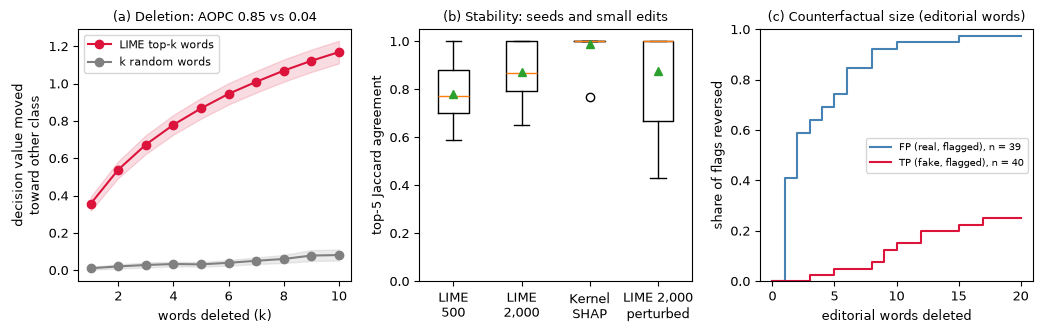

In [25]:
plt.rcParams.update({"font.size": 9})               # sized for a full-width figure in a printed report
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
m_l, m_r = curves_lime.mean(axis=0), curves_rand.mean(axis=0)
se_l, se_r = curves_lime.std(axis=0, ddof=1) / np.sqrt(len(curves_lime)), curves_rand.std(axis=0, ddof=1) / np.sqrt(len(curves_rand))
axes[0].plot(ks, m_l, marker="o", color="crimson", label="LIME top-k words")
axes[0].fill_between(ks, m_l - 1.96 * se_l, m_l + 1.96 * se_l, color="crimson", alpha=0.15)
axes[0].plot(ks, m_r, marker="o", color="grey", label="k random words")
axes[0].fill_between(ks, m_r - 1.96 * se_r, m_r + 1.96 * se_r, color="grey", alpha=0.15)
axes[0].set_xlabel("words deleted (k)"); axes[0].set_ylabel("decision value moved\ntoward other class")
axes[0].set_title(f"(a) Deletion: AOPC {aopc_lime.mean():.2f} vs {aopc_rand.mean():.2f}", fontsize=9.5); axes[0].legend(fontsize=8)
axes[1].boxplot(vals, tick_labels=["LIME\n500", "LIME\n2,000", "Kernel\nSHAP", "LIME 2,000\nperturbed"], showmeans=True)
axes[1].set_ylabel("top-5 Jaccard agreement"); axes[1].set_ylim(0, 1.05)
axes[1].set_title("(b) Stability: seeds and small edits", fontsize=9.5)
for g, color in [("FP (real, flagged)", "steelblue"), ("TP (fake, flagged)", "crimson")]:
    sizes = cf.loc[cf.group == g, "cf_size_editorial"]
    axes[2].step(ks_cf, [(sizes <= k).mean() for k in ks_cf], where="post", color=color, label=f"{g}, n = {len(sizes)}")
axes[2].set_xlabel("editorial words deleted"); axes[2].set_ylabel("share of flags reversed"); axes[2].set_ylim(0, 1)
axes[2].set_title("(c) Counterfactual size (editorial words)", fontsize=9.5); axes[2].legend(loc="center right", fontsize=7.5)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_report_xai_evidence.png", dpi=300); plt.show()
plt.rcParams.update({"font.size": 10})

## 8. Save All Numbers

In [26]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return o
with open(f"{RES_DIR}/xai_evaluation_results.json", "w") as fh:
    json.dump(to_jsonable(RESULTS), fh, indent=2)
print("Saved", f"{RES_DIR}/xai_evaluation_results.json")

Saved results/xai_evaluation_results.json


## 9. Summary of the Evidence

| Criterion | Test | Result |
|---|---|---|
| 2 Model vs baseline | Same test set, McNemar, bootstrap | SVM recall 0.9751 vs LR 0.9690 (+0.6 points, 95% CI 0.3 to 0.9); 33 vs 7 discordant wins, p = 4.2 × 10⁻⁵ |
| 3 Faithfulness | White-box LR: LIME vs exact contributions | Spearman ρ 0.81, precision@5 0.84, sign agreement 0.99 (50 articles) |
| 3 Faithfulness | White-box LR: KernelSHAP top-30 vs exact | error < 0.01 for 92% of articles, mean r 0.995 |
| 3 Faithfulness | White-box decision tree | 99.4% median LIME weight on the 5 tree terms; TreeSHAP exactly 0 on 4,995 unused terms |
| 3 Faithfulness | Deletion curve, SVM, 100 articles | AOPC 0.85 (LIME) vs 0.04 (random); flips after 5 deletions 17% vs 0% |
| 4 Stability | LIME, 10 seeds, 20 articles | top-5 Jaccard 0.78 (500 samples), 0.87 (2,000 samples); top word agrees 91% / 94% |
| 4 Stability | KernelSHAP top-30, 5 seeds | Jaccard 0.99 |
| 4 Stability | 5% token deletion, score change < 0.05 | Jaccard 0.877 vs 0.872 seed-only: no extra movement |
| 6 Actionability | Editorial-only counterfactuals | False positives: median 2 words, 64% within 3; true positives: 2.5% within 3 (no better than a score threshold at triage; value is the named words) |
| 8 Ethics | Error rates by group mention | Real articles mentioning race/ethnicity: FPR 3.6% (4/110) vs 0.85%; phi(featured, race mention) = 0.26 |
| 5 Human evidence | Forward simulation | **Pending**: materials in `human_eval/`, no participant data yet |

Limitations of these tests: 20 to 100 articles per test, one explained model, LIME at the notebook's settings, keyword lists for group mentions, and a deletion test that removes words the same way LIME perturbs them, which favours removal-based explainers. They measure faithfulness to the model, not whether the model's reasons are good ones: the evidence shows that LIME correctly reports a model that relies on source style, page layout and topic cues.